# XLM-RoBERTa: multilabel disease classification

Fine-tune **[FacebookAI/xlm-roberta-base](https://huggingface.co/FacebookAI/xlm-roberta-base)**
on `gold_standard.csv`. Each post can have zero, one, or several labels, in the fixed
order **AURI, PN, TB, COVID**. Outputs identify disease signals in posts.

The experiment excludes posts with conflicting annotations, deduplicates consistent
posts, and creates disjoint train/validation/test splits. The current CSV contains
21,968 rows; this policy retains **4,639 unique posts**, **518** with a disease label.
Excluding conflicts changes the population being evaluated. Historical ELECTRA
scores use a different data preparation/split and are not directly comparable.

Run all cells in order. The default `RUN_MODE = 'full'` trains on the prepared data.
For a quick pipeline check, set `RUN_MODE = 'smoke'`: the **same pretrained model**
trains for two optimizer steps on small stratified subsets. Smoke metrics are
pipeline diagnostics, never evidence of model quality. Restart from configuration
for a new experiment; each run gets a unique artifact directory.


## 1. Environment and configuration

Select the project's `.venv` kernel. If dependencies are missing, run this in a
separate notebook cell, then **restart the kernel**:

```python
%pip install "torch>=2.2" "transformers>=4.46,<6" "accelerate>=1.1" "sentencepiece>=0.2" "iterative-stratification==0.1.9" pandas numpy scipy scikit-learn matplotlib packaging
```

No installation happens automatically. The first model download needs internet
and roughly 1.1 GB for weights, plus space for checkpoints and saved models.
Set `LOCAL_FILES_ONLY = True` after the model is cached. Models and all reports
stay beneath `artifacts/disease_xlmr/`; no external tracking or upload is used.

This notebook uses [Hugging Face Trainer](https://huggingface.co/docs/transformers/main_classes/trainer)
and [iterative multilabel stratification](https://github.com/trent-b/iterative-stratification).
Apple MPS is preferred on Mac; CPU is the fallback. Both use full precision.


In [1]:
import ast
import gc
import hashlib
import json
import math
import platform
import re
import sys
import uuid
from datetime import datetime, timezone
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

from packaging.version import Version

REQUIRED = {
    'torch': '2.2', 'transformers': '4.46', 'accelerate': '1.1',
    'sentencepiece': '0.2', 'iterative-stratification': '0.1.9',
    'pandas': '2.0', 'numpy': '1.26', 'scipy': '1.11',
    'scikit-learn': '1.4', 'matplotlib': '3.8',
}
PACKAGE_VERSIONS, dependency_errors = {}, []
for package, minimum in REQUIRED.items():
    try:
        installed = version(package)
        PACKAGE_VERSIONS[package] = installed
        if Version(installed) < Version(minimum):
            dependency_errors.append(f'{package}>={minimum} (installed {installed})')
    except PackageNotFoundError:
        dependency_errors.append(f'{package}>={minimum} (missing)')
if dependency_errors:
    raise ImportError('Install dependencies in this kernel and restart: ' + ', '.join(dependency_errors))
if Version(PACKAGE_VERSIONS['transformers']).major >= 6:
    raise ImportError('This notebook targets Transformers 4.46–5.x; use transformers<6.')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from scipy.special import expit
from sklearn.metrics import (
    accuracy_score, f1_score, hamming_loss, multilabel_confusion_matrix,
    precision_recall_fscore_support,
)
from transformers import (
    AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
    EarlyStoppingCallback, Trainer, TrainingArguments, set_seed,
)


def normalize_text(text):
    if not isinstance(text, str) or not text.strip():
        raise ValueError('text must be a non-empty string')
    return re.sub(r'\s+', ' ', text).strip()


def write_json(path, payload):
    Path(path).write_text(json.dumps(payload, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')


def select_device(preference='auto'):
    if preference not in {'auto', 'mps', 'cpu'}:
        raise ValueError('DEVICE_PREFERENCE must be auto, mps, or cpu')
    available = hasattr(torch.backends, 'mps') and torch.backends.mps.is_available()
    if preference == 'mps' and not available:
        raise RuntimeError('MPS is unavailable in this kernel. Select cpu or use an MPS-enabled kernel.')
    return torch.device('mps' if available and preference != 'cpu' else 'cpu')


print('Python:', sys.executable, platform.python_version())
display(pd.Series(PACKAGE_VERSIONS, name='version').to_frame())


/Users/gelo-p1/Documents/GitHub/HealthPH-Plus/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: /Users/gelo-p1/Documents/GitHub/HealthPH-Plus/.venv/bin/python 3.14.6


,version
torch,2.14.0
transformers,5.16.1
accelerate,1.14.0
sentencepiece,0.2.2
iterative-stratification,0.1.9
pandas,3.0.3
numpy,2.5.1
scipy,1.18.0
scikit-learn,1.9.0
matplotlib,3.11.0


In [2]:
# Edit these settings before running subsequent cells.
RUN_MODE = 'full'  # 'full' or 'smoke'; smoke is NOT an accuracy experiment.
DEVICE_PREFERENCE = 'auto'
LOCAL_FILES_ONLY = False
MODEL_NAME = 'FacebookAI/xlm-roberta-base'
MODEL_REVISION = 'main'  # The resolved Hub commit is recorded with the run.
DATASET_PATH = None  # Optional absolute path to a CSV with post and annotate columns.

SEED = 42
LABELS = ['AURI', 'PN', 'TB', 'COVID']
LABEL2ID = {label: index for index, label in enumerate(LABELS)}
ID2LABEL = {index: label for label, index in LABEL2ID.items()}
NORMALIZATION = 'collapse whitespace and strip; preserve casing and Unicode'
TEST_SIZE, VAL_SIZE = 0.10, 0.10
MAX_LENGTH = 128
BATCH_SIZE = 4
GRADIENT_ACCUMULATION_STEPS = 4
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10
NUM_EPOCHS = 5
EARLY_STOPPING_PATIENCE = 2
SMOKE_STEPS = 2
SMOKE_SIZES = {'train': 64, 'validation': 32, 'test': 32}
THRESHOLD_GRID = np.round(np.arange(5, 96) / 100, 2)

if RUN_MODE not in {'full', 'smoke'}:
    raise ValueError('RUN_MODE must be full or smoke')
ROOT_DIR = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / 'notebooks').is_dir() and (p / 'README.md').is_file()), None,
)
if ROOT_DIR is None:
    raise FileNotFoundError('Open the notebook from the HealthPH-Plus repository or its notebooks directory.')
DATA_PATH = Path(DATASET_PATH).expanduser().resolve() if DATASET_PATH else ROOT_DIR / 'data/training_data/gold_standard.csv'
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'CSV not found: {DATA_PATH}. Set DATASET_PATH explicitly.')
ARTIFACT_ROOT = ROOT_DIR / 'artifacts/disease_xlmr'
HF_CACHE_DIR = ARTIFACT_ROOT / '.hf_cache'
RUN_ID = f"{RUN_MODE}_{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}_{uuid.uuid4().hex[:8]}"
RUN_DIR = ARTIFACT_ROOT / RUN_ID
REPORT_DIR = RUN_DIR / 'reports'
REPORT_DIR.mkdir(parents=True, exist_ok=False)
HF_CACHE_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = select_device(DEVICE_PREFERENCE)
set_seed(SEED)

print('Mode:', RUN_MODE, '| Device:', DEVICE)
print('Dataset:', DATA_PATH)
print('Artifacts:', RUN_DIR)
if RUN_MODE == 'smoke':
    print('SMOKE RUN: two optimizer steps; every reported metric is a pipeline diagnostic.')


Mode: full | Device: mps
Dataset: /Users/gelo-p1/Documents/GitHub/HealthPH-Plus/data/training_data/gold_standard.csv
Artifacts: /Users/gelo-p1/Documents/GitHub/HealthPH-Plus/artifacts/disease_xlmr/full_20261001T044257Z_9bcb95ca


## 2. Validate annotations and exclude conflicts

Parse label strings with `ast.literal_eval`; accept only a four-element list of
integer zeros and ones (booleans and floats are invalid). Read literal strings
such as `NA` without converting them to missing values. Invalid rows stop the run
with source-row references. `source_row` is the 1-based data-record number, excluding
the CSV header; quoted multiline records still count as one record.

Normalize whitespace, then compare complete label vectors for each post. Exclude
**all** rows belonging to a conflicting post; do not vote, merge labels, or prefer
the first annotation. For consistent groups, retain the first row and preserve
references to every source record. The original CSV is never modified.


In [3]:
def parse_labels(value):
    if not isinstance(value, str):
        raise ValueError('annotate must be a string containing a list')
    try:
        result = ast.literal_eval(value)
    except (SyntaxError, ValueError) as exc:
        raise ValueError('annotate must be a literal list of four binary integers') from exc
    if (not isinstance(result, list) or len(result) != 4
            or any(type(item) is not int or item not in (0, 1) for item in result)):
        raise ValueError('annotate must contain exactly four integer zeros/ones')
    return result


def prepare_annotations(raw):
    missing = {'post', 'annotate'} - set(raw.columns)
    if missing:
        raise ValueError(f'Missing columns: {sorted(missing)}')
    if raw.empty:
        raise ValueError('Dataset is empty')
    records, invalid = [], []
    for source_row, (post, annotate) in enumerate(raw[['post', 'annotate']].itertuples(index=False, name=None), 1):
        try:
            text = normalize_text(post)
            labels = parse_labels(annotate)
        except ValueError as exc:
            invalid.append({'source_row': source_row, 'error': str(exc)})
            continue
        records.append({
            'source_row': source_row, 'post': post, 'annotate': annotate, 'text': text,
            'text_fingerprint': hashlib.sha256(text.encode('utf-8')).hexdigest(),
            'label_key': tuple(labels), **dict(zip(LABELS, labels)),
        })
    if invalid:
        raise ValueError(f'{len(invalid)} invalid rows; first examples: {invalid[:10]}')
    frame = pd.DataFrame(records)
    groups = frame.groupby('text', sort=False)
    conflict_texts = set(groups['label_key'].nunique().loc[lambda counts: counts > 1].index)
    conflict_mask = frame['text'].isin(conflict_texts)
    conflicts = frame.loc[conflict_mask].copy().assign(exclusion_reason='conflicting_annotations')
    consistent = frame.loc[~conflict_mask].copy()
    duplicates = consistent.loc[consistent.duplicated('text')].copy().assign(exclusion_reason='consistent_duplicate')
    source_rows = consistent.groupby('text', sort=False)['source_row'].agg(list).map(json.dumps)
    kept = consistent.drop_duplicates('text').copy()
    kept['source_rows'] = kept['text'].map(source_rows)
    kept = kept.drop(columns=['label_key']).reset_index(drop=True)
    conflicts = conflicts.drop(columns=['label_key']).reset_index(drop=True)
    duplicates = duplicates.drop(columns=['label_key']).reset_index(drop=True)
    if kept.empty:
        raise ValueError('No consistently annotated posts remain')
    assert len(kept) + len(conflicts) + len(duplicates) == len(raw)
    assert kept['text'].is_unique and kept['text_fingerprint'].is_unique
    assert set(kept['text']).isdisjoint(conflict_texts)
    audit = {
        'raw_rows': len(raw), 'unique_normalized_posts': int(frame['text'].nunique()),
        'conflicting_posts': len(conflict_texts), 'conflicting_rows_excluded': len(conflicts),
        'consistent_duplicate_rows_removed': len(duplicates), 'retained_posts': len(kept),
        'posts_with_any_disease': int(kept[LABELS].any(axis=1).sum()),
        'all_zero_posts': int((kept[LABELS].sum(axis=1) == 0).sum()),
        'raw_label_counts': {label: int(frame[label].sum()) for label in LABELS},
        'retained_label_counts': {label: int(kept[label].sum()) for label in LABELS},
        'normalization': NORMALIZATION, 'conflict_policy': 'exclude_entire_post_group',
    }
    return kept, conflicts, duplicates, audit


def split_annotations(frame):
    splitter = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED)
    trainval_idx, test_idx = next(splitter.split(np.zeros(len(frame)), frame[LABELS].to_numpy()))
    trainval = frame.iloc[trainval_idx].reset_index(drop=True)
    splitter = MultilabelStratifiedShuffleSplit(
        n_splits=1, test_size=VAL_SIZE / (1 - TEST_SIZE), random_state=SEED,
    )
    train_idx, val_idx = next(splitter.split(np.zeros(len(trainval)), trainval[LABELS].to_numpy()))
    return {
        'train': trainval.iloc[train_idx].reset_index(drop=True),
        'validation': trainval.iloc[val_idx].reset_index(drop=True),
        'test': frame.iloc[test_idx].reset_index(drop=True),
    }


def assert_valid_splits(parts):
    for name, frame in parts.items():
        if frame.empty or not frame['text_fingerprint'].is_unique:
            raise ValueError(f'{name}: split is empty or contains duplicate posts')
        counts = frame[LABELS].sum()
        if ((counts == 0) | (counts == len(frame))).any():
            raise ValueError(f'{name}: every label needs positive and negative examples; counts={counts.to_dict()}')
    for left, right in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
        assert set(parts[left]['text_fingerprint']).isdisjoint(parts[right]['text_fingerprint'])


def smoke_subset(frame, target_size):
    if len(frame) <= target_size:
        return frame.copy()
    sampler = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=target_size, random_state=SEED)
    _, selected = next(sampler.split(np.zeros(len(frame)), frame[LABELS].to_numpy()))
    return frame.iloc[selected].reset_index(drop=True)


{
  "raw_rows": 21968,
  "unique_normalized_posts": 6290,
  "conflicting_posts": 1651,
  "conflicting_rows_excluded": 6710,
  "consistent_duplicate_rows_removed": 10619,
  "retained_posts": 4639,
  "posts_with_any_disease": 518,
  "all_zero_posts": 4121,
  "raw_label_counts": {
    "AURI": 4051,
    "PN": 2838,
    "TB": 3408,
    "COVID": 3952
  },
  "retained_label_counts": {
    "AURI": 438,
    "PN": 335,
    "TB": 334,
    "COVID": 472
  },
  "normalization": "collapse whitespace and strip; preserve casing and Unicode",
  "conflict_policy": "exclude_entire_post_group",
  "dataset_sha256": "4815a5446861d3bda4c38f20ce5a5833453b1507a51ec40c984b2ce64266b760",
  "dataset_path": "/Users/gelo-p1/Documents/GitHub/HealthPH-Plus/data/training_data/gold_standard.csv"
}


,split,rows,any_disease,AURI,PN,TB,COVID
0,train,3711,414,350,268,268,378
1,validation,464,51,44,33,33,47
2,test,464,53,44,34,33,47


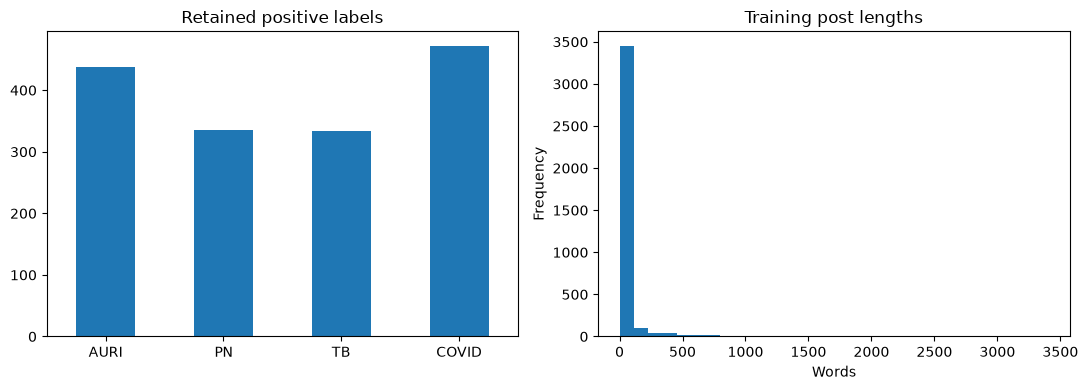

In [4]:
raw_df = pd.read_csv(DATA_PATH, dtype=str, encoding='utf-8-sig', keep_default_na=False)
clean_df, conflicts_df, duplicates_df, data_audit = prepare_annotations(raw_df)
data_audit['dataset_sha256'] = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
data_audit['dataset_path'] = str(DATA_PATH)
write_json(REPORT_DIR / 'data_audit.json', data_audit)
conflicts_df.to_csv(REPORT_DIR / 'excluded_conflicting_rows.csv', index=False)
duplicates_df.to_csv(REPORT_DIR / 'removed_consistent_duplicates.csv', index=False)
print(json.dumps(data_audit, indent=2, ensure_ascii=False))

full_splits = split_annotations(clean_df)
assert_valid_splits(full_splits)
assert sum(map(len, full_splits.values())) == len(clean_df)
repeated_splits = split_annotations(clean_df)
for name in full_splits:
    assert full_splits[name]['text_fingerprint'].tolist() == repeated_splits[name]['text_fingerprint'].tolist()

manifest_columns = ['source_row', 'source_rows', 'text_fingerprint', *LABELS, 'split']
full_manifest = pd.concat([frame.assign(split=name) for name, frame in full_splits.items()], ignore_index=True)
full_manifest[manifest_columns].to_csv(REPORT_DIR / 'split_manifest.csv', index=False)
splits = ({name: smoke_subset(frame, SMOKE_SIZES[name]) for name, frame in full_splits.items()}
          if RUN_MODE == 'smoke' else full_splits)
assert_valid_splits(splits)
active_manifest = pd.concat([frame.assign(split=name) for name, frame in splits.items()], ignore_index=True)
active_manifest[manifest_columns].to_csv(REPORT_DIR / 'active_split_manifest.csv', index=False)
train_df, val_df, test_df = (splits[name] for name in ['train', 'validation', 'test'])

split_summary = pd.DataFrame([
    {'split': name, 'rows': len(frame), 'any_disease': int(frame[LABELS].any(axis=1).sum()),
     **{label: int(frame[label].sum()) for label in LABELS}}
    for name, frame in splits.items()
])
split_summary.to_csv(REPORT_DIR / 'split_summary.csv', index=False)
display(split_summary)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
clean_df[LABELS].sum().plot.bar(ax=axes[0], title='Retained positive labels', rot=0)
train_df['text'].str.split().str.len().plot.hist(ax=axes[1], bins=30, title='Training post lengths')
axes[1].set_xlabel('Words')
fig.tight_layout()
fig.savefig(REPORT_DIR / 'data_overview.png', dpi=140)
plt.show()


## 3. Metrics, thresholds, and data checks

Sigmoid scores are independent for each disease and do not sum to one. Predict a
label when its score is **greater than or equal to** its threshold. The checkpoint
metric is validation micro-F1 at 0.5. Threshold tuning happens **after** checkpoint
selection, independently for each label, using validation F1. Ties prefer the
threshold nearest 0.5, then the lower value. No test prediction is used for either
selection. Exact-match accuracy can be misleading here because most posts have no
disease label; always inspect per-disease recall and F1.


In [5]:
def validate_probabilities(probabilities):
    probabilities = np.asarray(probabilities, dtype=np.float64)
    if probabilities.ndim != 2 or probabilities.shape[1] != 4:
        raise ValueError('Expected an N x 4 probability array')
    if not np.isfinite(probabilities).all() or not ((probabilities >= 0) & (probabilities <= 1)).all():
        raise ValueError('Probabilities must be finite values in [0, 1]')
    return probabilities


def apply_thresholds(probabilities, thresholds):
    probabilities = validate_probabilities(probabilities)
    thresholds = np.asarray(thresholds, dtype=np.float64)
    if thresholds.shape != (4,) or not np.isfinite(thresholds).all() or not ((thresholds >= 0) & (thresholds <= 1)).all():
        raise ValueError('Expected four finite thresholds in [0, 1]')
    return (probabilities >= thresholds).astype(int)


def summarize_metrics(labels, probabilities, thresholds):
    labels = np.asarray(labels)
    predictions = apply_thresholds(probabilities, thresholds)
    if labels.shape != predictions.shape or len(labels) == 0 or not np.isin(labels, [0, 1]).all():
        raise ValueError('Expected nonempty N x 4 binary labels matching probabilities')
    metrics = {
        'rows': int(len(labels)), 'exact_match_accuracy': float(accuracy_score(labels, predictions)),
        'hamming_loss': float(hamming_loss(labels, predictions)),
    }
    for average in ['micro', 'macro']:
        precision, recall, f1, _ = precision_recall_fscore_support(labels, predictions, average=average, zero_division=0)
        metrics.update({f'{average}_precision': float(precision), f'{average}_recall': float(recall), f'{average}_f1': float(f1)})
    precision, recall, f1, support = precision_recall_fscore_support(labels, predictions, average=None, zero_division=0)
    per_label = pd.DataFrame({
        'label': LABELS, 'precision': precision, 'recall': recall, 'f1': f1,
        'support': support.astype(int), 'threshold': thresholds,
    })
    matrices = multilabel_confusion_matrix(labels, predictions)
    return metrics, per_label, matrices, predictions


def tune_thresholds(labels, probabilities):
    labels = np.asarray(labels)
    probabilities = validate_probabilities(probabilities)
    if labels.shape != probabilities.shape or len(labels) == 0 or not np.isin(labels, [0, 1]).all():
        raise ValueError('Invalid labels for threshold search')
    rows, selected = [], []
    for index, label in enumerate(LABELS):
        candidates = [
            {'label': label, 'threshold': float(threshold),
             'f1': float(f1_score(labels[:, index], probabilities[:, index] >= threshold, zero_division=0)),
             'distance_from_0_5': round(abs(float(threshold) - 0.5), 8)}
            for threshold in THRESHOLD_GRID
        ]
        ranked = sorted(candidates, key=lambda row: (-row['f1'], row['distance_from_0_5'], row['threshold']))
        selected.append(ranked[0]['threshold'])
        rows.extend(candidates)
    return np.asarray(selected), pd.DataFrame(rows)


def compute_checkpoint_metrics(prediction):
    logits = prediction.predictions[0] if isinstance(prediction.predictions, tuple) else prediction.predictions
    metrics, _, _, _ = summarize_metrics(prediction.label_ids, expit(logits), np.full(4, 0.5))
    return {key: value for key, value in metrics.items() if key != 'rows'}


In [6]:
# Small checks run before downloading or training the model.
def expect_value_error(fn, *args):
    try:
        fn(*args)
    except ValueError:
        return
    raise AssertionError(f'{fn.__name__} did not reject {args!r}')


for malformed in ['not a list', '[1,0,0]', '[1,0,0,0,0]', '[1,2,0,0]',
                  '[True,0,0,0]', '[1.0,0,0,0]', '(1,0,0,0)', 'null', None]:
    expect_value_error(parse_labels, malformed)
for blank in ['', '  ', None, 12]:
    expect_value_error(normalize_text, blank)
assert parse_labels('[1, 0, 1, 0]') == [1, 0, 1, 0]
assert normalize_text('  Ubo\n at  lagnat — café  ') == 'Ubo at lagnat — café'
fixture = pd.DataFrame({
    'post': ['Same  post', 'Same post', 'conflict', ' conflict ', 'NA'],
    'annotate': ['[1,0,0,1]', '[1,0,0,1]', '[0,0,0,0]', '[0,1,0,0]', '[0,0,0,0]'],
})
kept, excluded, duplicated, audit = prepare_annotations(fixture)
assert kept['text'].tolist() == ['Same post', 'NA']
assert json.loads(kept.iloc[0]['source_rows']) == [1, 2]
assert len(excluded) == 2 and len(duplicated) == 1 and audit['conflicting_posts'] == 1
expect_value_error(prepare_annotations, pd.DataFrame({'post': [''], 'annotate': ['[0,0,0,0]']}))
expect_value_error(prepare_annotations, pd.DataFrame({'post': ['valid']}))

boundary = np.array([[0.5, 0.49, 0.51, 0.5], [0.0, 0.0, 0.0, 0.0]])
assert apply_thresholds(boundary, [0.5] * 4).tolist() == [[1, 0, 1, 1], [0, 0, 0, 0]]
for invalid in [np.ones((2, 3)), np.full((2, 4), np.nan), np.full((2, 4), 1.1)]:
    expect_value_error(apply_thresholds, invalid, [0.5] * 4)
assert tune_thresholds(np.zeros((3, 4)), np.zeros((3, 4)))[0].tolist() == [0.5] * 4
perfect = np.array([[1, 0, 1, 0], [0, 1, 0, 1]])
assert summarize_metrics(perfect, perfect.astype(float), [0.5] * 4)[0]['micro_f1'] == 1.0
print('Annotation, conflict, split, metric, and threshold checks passed.')


Annotation, conflict, split, metric, and threshold checks passed.


## 4. Fine-tune XLM-RoBERTa

Every run loads the pretrained encoder and initializes a new four-label head.
There is **no automatic resume** from prior disease checkpoints. Positive loss
weights are `training negatives / training positives`, separately for each label.
Weighted loss emphasizes rare positive labels; sigmoid scores are not calibrated
clinical probabilities. Thresholds will be selected on validation data.

The custom Trainer returns a microbatch-mean loss and disables loss-kwargs handling,
so Trainer applies gradient-accumulation scaling. Dynamic padding pads only to the
longest input in each batch. Posts are truncated at 128 tokens, including special
tokens; training/validation truncation rates are shown before training.


In [7]:
class DiseaseDataset(torch.utils.data.Dataset):
    def __init__(self, frame, tokenizer):
        self.encodings = tokenizer(frame['text'].tolist(), truncation=True, max_length=MAX_LENGTH, padding=False)
        self.labels = frame[LABELS].to_numpy(dtype=np.float32).tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return {**{key: values[index] for key, values in self.encodings.items()}, 'labels': self.labels[index]}


class WeightedMultilabelTrainer(Trainer):
    def __init__(self, *args, positive_weights, **kwargs):
        super().__init__(*args, **kwargs)
        self.positive_weights = positive_weights.detach().clone()
        self.model_accepts_loss_kwargs = False

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        model_inputs = dict(inputs)
        labels = model_inputs.pop('labels').float()
        outputs = model(**model_inputs)
        logits = outputs.logits.float()
        loss = torch.nn.functional.binary_cross_entropy_with_logits(
            logits, labels.to(logits.device),
            pos_weight=self.positive_weights.to(logits.device), reduction='mean',
        )
        return (loss, outputs) if return_outputs else loss


def make_training_arguments(training_rows):
    steps_per_epoch = math.ceil(math.ceil(training_rows / BATCH_SIZE) / GRADIENT_ACCUMULATION_STEPS)
    total_steps = SMOKE_STEPS if RUN_MODE == 'smoke' else steps_per_epoch * NUM_EPOCHS
    kwargs = dict(
        output_dir=str(RUN_DIR / 'checkpoints'),
        learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
        per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=BATCH_SIZE,
        gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
        num_train_epochs=NUM_EPOCHS, warmup_steps=math.ceil(total_steps * WARMUP_RATIO),
        optim='adamw_torch', fp16=False, bf16=False,
        gradient_checkpointing=True, gradient_checkpointing_kwargs={'use_reentrant': False},
        eval_strategy='epoch', save_strategy='epoch', logging_strategy='epoch',
        load_best_model_at_end=True, metric_for_best_model='micro_f1', greater_is_better=True,
        save_total_limit=1, save_only_model=True,
        dataloader_num_workers=0, dataloader_pin_memory=False,
        report_to='none', push_to_hub=False, seed=SEED, data_seed=SEED,
        use_cpu=(DEVICE.type == 'cpu'), disable_tqdm=(RUN_MODE == 'smoke'),
    )
    if RUN_MODE == 'smoke':
        kwargs.update(max_steps=SMOKE_STEPS, eval_strategy='steps', eval_steps=SMOKE_STEPS,
                      save_strategy='steps', save_steps=SMOKE_STEPS,
                      logging_strategy='steps', logging_steps=1)
    return TrainingArguments(**kwargs)


def token_length_audit(frame, tokenizer):
    lengths = np.array([len(ids) for ids in tokenizer(frame['text'].tolist(), truncation=False, padding=False)['input_ids']])
    return {'rows': len(frame), 'median_tokens': float(np.median(lengths)),
            'max_tokens': int(lengths.max()), 'truncated_posts': int((lengths > MAX_LENGTH).sum()),
            'truncated_fraction': float((lengths > MAX_LENGTH).mean())}


def prediction_probabilities(output, expected_labels):
    np.testing.assert_array_equal(output.label_ids, expected_labels)
    logits = output.predictions[0] if isinstance(output.predictions, tuple) else output.predictions
    return validate_probabilities(expit(logits))


In [ ]:
set_seed(SEED)
try:
    tokenizer = AutoTokenizer.from_pretrained(
        MODEL_NAME, revision=MODEL_REVISION, cache_dir=HF_CACHE_DIR,
        local_files_only=LOCAL_FILES_ONLY, use_fast=True, trust_remote_code=False,
    )
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, revision=MODEL_REVISION, cache_dir=HF_CACHE_DIR,
        local_files_only=LOCAL_FILES_ONLY, trust_remote_code=False,
        num_labels=4, problem_type='multi_label_classification',
        id2label=ID2LABEL, label2id=LABEL2ID,
    ).float()
except OSError as exc:
    raise RuntimeError(
        'Could not load XLM-R. The first run needs internet; offline runs need a complete '
        f'cache at {HF_CACHE_DIR}. No alternate model or random encoder is substituted.'
    ) from exc

resolved_revision = getattr(model.config, '_commit_hash', None)
train_counts = train_df[LABELS].sum().to_numpy(dtype=np.float32)
positive_weights = torch.tensor((len(train_df) - train_counts) / train_counts, dtype=torch.float32)

assert torch.isfinite(positive_weights).all() and (positive_weights > 0).all()
print('Training-only positive weights:', dict(zip(LABELS, positive_weights.tolist())))

token_audits = {name: token_length_audit(splits[name], tokenizer) for name in ['train', 'validation']}
display(pd.DataFrame(token_audits).T)

train_ds, val_ds = DiseaseDataset(train_df, tokenizer), DiseaseDataset(val_df, tokenizer)
collator = DataCollatorWithPadding(tokenizer=tokenizer, return_tensors='pt')
training_args = make_training_arguments(len(train_df))
if training_args.device.type != DEVICE.type:
    raise RuntimeError(f'Trainer chose {training_args.device}, but configuration selected {DEVICE}')
trainer = WeightedMultilabelTrainer(
    model=model, args=training_args, train_dataset=train_ds, eval_dataset=val_ds,
    data_collator=collator, processing_class=tokenizer, positive_weights=positive_weights,
    compute_metrics=compute_checkpoint_metrics,
    callbacks=[] if RUN_MODE == 'smoke' else [EarlyStoppingCallback(early_stopping_patience=EARLY_STOPPING_PATIENCE)],
)

# Verify the actual collator/model/loss contract before expensive training.
probe = {key: value.to(DEVICE) for key, value in collator([train_ds[0], train_ds[1]]).items()}
trainer.model.eval()
with torch.no_grad():
    probe_loss, probe_output = trainer.compute_loss(trainer.model, probe, return_outputs=True)
    expected_loss = torch.nn.functional.binary_cross_entropy_with_logits(
        probe_output.logits.float(), probe['labels'].float(), pos_weight=positive_weights.to(DEVICE),
    )
assert probe_output.logits.shape == (2, 4) and torch.isfinite(probe_loss)
torch.testing.assert_close(probe_loss, expected_loss)
assert trainer.model_accepts_loss_kwargs is False
print('Pretrained model, collator, and weighted loss checks passed. Resolved revision:', resolved_revision)
del probe, probe_output, probe_loss, expected_loss

run_config = {
    'run_id': RUN_ID, 'run_mode': RUN_MODE, 'smoke_only': RUN_MODE == 'smoke',
    'model_name': MODEL_NAME, 'requested_revision': MODEL_REVISION, 'resolved_revision': resolved_revision,
    'dataset_path': str(DATA_PATH), 'dataset_sha256': data_audit['dataset_sha256'],
    'input_column': 'post', 'target_column': 'annotate', 'label_order': LABELS,
    'normalization': NORMALIZATION, 'conflict_policy': 'exclude_entire_post_group',
    'seed': SEED, 'split_fractions': {'train': 0.8, 'validation': 0.1, 'test': 0.1},
    'split_algorithm': 'MultilabelStratifiedShuffleSplit; test first, then validation',
    'active_split_sizes': {name: len(frame) for name, frame in splits.items()},
    'max_length': MAX_LENGTH, 'batch_size': BATCH_SIZE,
    'gradient_accumulation_steps': GRADIENT_ACCUMULATION_STEPS,
    'learning_rate': LEARNING_RATE, 'weight_decay': WEIGHT_DECAY,
    'warmup_ratio': WARMUP_RATIO, 'warmup_steps': training_args.warmup_steps,
    'max_epochs': NUM_EPOCHS, 'max_steps': training_args.max_steps,
    'early_stopping_patience': None if RUN_MODE == 'smoke' else EARLY_STOPPING_PATIENCE,
    'loss': 'BCEWithLogitsLoss, training negatives / positives, mean reduction',
    'positive_weights': dict(zip(LABELS, positive_weights.tolist())),
    'checkpoint_metric': 'validation micro_f1 at threshold 0.5',
    'precision': 'float32', 'gradient_checkpointing': True,
    'device': str(DEVICE), 'python_version': platform.python_version(), 'versions': PACKAGE_VERSIONS,
    'historical_electra_comparison_valid': False,
}
write_json(RUN_DIR / 'run_config.json', run_config)


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 10309.14it/s]
[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers

Training-only positive weights: {'AURI': 9.60285758972168, 'PN': 12.847015380859375, 'TB': 12.847015380859375, 'COVID': 8.817460060119629}


,rows,median_tokens,max_tokens,truncated_posts,truncated_fraction
train,3711.0,29.0,5043.0,289.0,0.077877
validation,464.0,28.0,3689.0,43.0,0.092672


Pretrained model, collator, and weighted loss checks passed. Resolved revision: e73636d4f797dec63c3081bb6ed5c7b0bb3f2089


In [9]:
# This is the expensive cell. Fresh training only; never reuse another experiment's weights.
train_result = trainer.train(resume_from_checkpoint=False)
if trainer.state.best_model_checkpoint is None:
    raise RuntimeError('Training did not produce a validation-selected checkpoint')
validation_output = trainer.predict(val_ds, metric_key_prefix='validation')
validation_probabilities = prediction_probabilities(validation_output, val_df[LABELS].to_numpy())
print('Best checkpoint:', trainer.state.best_model_checkpoint)
print('Best validation micro-F1 at 0.5:', trainer.state.best_metric)
if RUN_MODE == 'smoke':
    print('SMOKE ONLY: these scores do not measure a fully trained classifier.')


Epoch,Training Loss,Validation Loss,Exact Match Accuracy,Hamming Loss,Micro Precision,Micro Recall,Micro F1,Macro Precision,Macro Recall,Macro F1,Runtime,Samples Per Second,Steps Per Second
1,1.116381,0.704225,0.894397,0.070043,0.559471,0.808917,0.661458,0.555157,0.806294,0.655722,2.942300,157.701000,39.425000
2,0.833950,0.441932,0.892241,0.076509,0.527076,0.929936,0.672811,0.522391,0.924968,0.666685,3.176200,146.085000,36.521000
3,0.678212,0.534287,0.909483,0.058190,0.605150,0.898089,0.723077,0.601200,0.893133,0.716726,2.809600,165.149000,41.287000
4,0.527809,0.621084,0.924569,0.046336,0.680203,0.853503,0.757062,0.676750,0.848404,0.750001,2.827900,164.077000,41.019000
5,0.445268,0.671658,0.922414,0.044720,0.690722,0.853503,0.763533,0.686498,0.848404,0.756613,2.799400,165.749000,41.437000


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.94it/s]


Best checkpoint: /Users/gelo-p1/Documents/GitHub/HealthPH-Plus/artifacts/disease_xlmr/full_20261001T044257Z_9bcb95ca/checkpoints/checkpoint-1160
Best validation micro-F1 at 0.5: 0.7635327635327636


## 5. Freeze thresholds and save the selected model

This cell sees validation labels only. It saves the chosen checkpoint, tokenizer,
thresholds, and fixed label order **before** test evaluation. The threshold search
covers 0.05 through 0.95 inclusive at increments of 0.01.


In [10]:
selected_thresholds, threshold_search = tune_thresholds(val_df[LABELS].to_numpy(), validation_probabilities)
frozen_thresholds = selected_thresholds.copy()
frozen_thresholds.setflags(write=False)
threshold_search.to_csv(REPORT_DIR / 'validation_threshold_search.csv', index=False)
threshold_payload = {label: float(frozen_thresholds[index]) for index, label in enumerate(LABELS)}
write_json(RUN_DIR / 'thresholds.json', threshold_payload)
write_json(RUN_DIR / 'label_order.json', LABELS)
write_json(RUN_DIR / 'selection.json', {
    'run_mode': RUN_MODE, 'smoke_only': RUN_MODE == 'smoke',
    'best_checkpoint': str(trainer.state.best_model_checkpoint),
    'best_validation_micro_f1_at_0_5': float(trainer.state.best_metric),
    'threshold_objective': 'per-label validation F1',
    'threshold_grid': THRESHOLD_GRID.tolist(),
    'threshold_tie_break': 'closest to 0.5, then lower threshold',
    'thresholds': threshold_payload, 'test_used_for_selection': False,
})
trainer.save_model(str(RUN_DIR / 'best_model'))
tokenizer.save_pretrained(RUN_DIR / 'best_model')
print('Frozen thresholds:', threshold_payload)


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.56it/s]

Frozen thresholds: {'AURI': 0.89, 'PN': 0.75, 'TB': 0.79, 'COVID': 0.78}


## 6. Evaluate the held-out test split

Evaluate test data once with the frozen checkpoint and thresholds. The always-no-
disease reference predicts four zeros. Scores at threshold 0.5 are also reported
for context; neither test table is used to choose thresholds or models. Report
support counts alongside F1 because the retained positive population is small.


Held-out evaluation


,run_mode,split,model,rows,exact_match_accuracy,hamming_loss,micro_precision,micro_recall,micro_f1,macro_precision,macro_recall,macro_f1
0,full,validation,xlmr_tuned,464,0.937500,0.035022,0.767442,0.840764,0.802432,0.761833,0.835509,0.794828
1,full,validation,xlmr_at_0_5,464,0.922414,0.044720,0.690722,0.853503,0.763533,0.686498,0.848404,0.756613
2,full,validation,always_no_disease,464,0.890086,0.084591,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,full,test,xlmr_tuned,464,0.924569,0.042565,0.751592,0.746835,0.749206,0.743381,0.736330,0.738643
4,full,test,xlmr_at_0_5,464,0.915948,0.046336,0.702247,0.791139,0.744048,0.698391,0.784764,0.737407
5,full,test,always_no_disease,464,0.885776,0.085129,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


,label,precision,recall,f1,support,threshold,run_mode,split,model
12,AURI,0.897436,0.795455,0.843373,44,0.89,full,test,xlmr_tuned
13,PN,0.694444,0.735294,0.714286,34,0.75,full,test,xlmr_tuned
14,TB,0.555556,0.606061,0.579710,33,0.79,full,test,xlmr_tuned
15,COVID,0.826087,0.808511,0.817204,47,0.78,full,test,xlmr_tuned


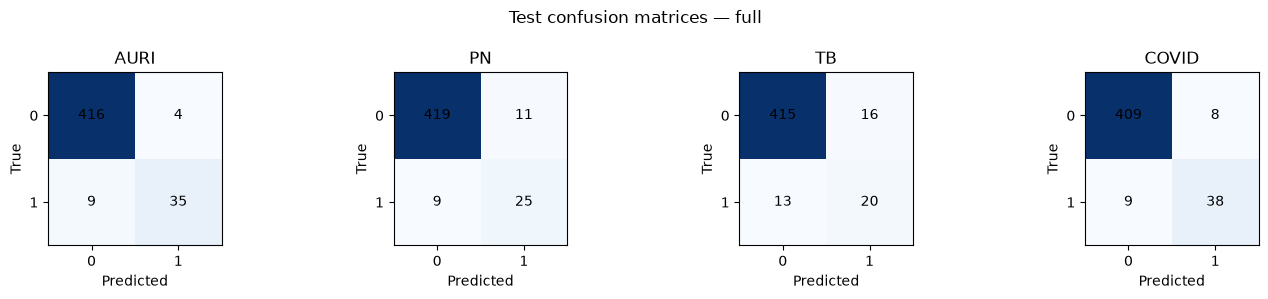

In [11]:
test_ds = DiseaseDataset(test_df, tokenizer)
token_audits['test'] = token_length_audit(test_df, tokenizer)
write_json(REPORT_DIR / 'token_length_audit.json', token_audits)
test_output = trainer.predict(test_ds, metric_key_prefix='test')
test_probabilities = prediction_probabilities(test_output, test_df[LABELS].to_numpy())
metric_rows, per_label_tables, confusion_rows = [], [], []
metrics_payload = {'run_mode': RUN_MODE, 'smoke_only': RUN_MODE == 'smoke', 'splits': {}}

for split_name, frame, probabilities in [
    ('validation', val_df, validation_probabilities), ('test', test_df, test_probabilities),
]:
    labels = frame[LABELS].to_numpy(dtype=int)
    metrics_payload['splits'][split_name] = {}
    for variant, scores, cutoffs in [
        ('xlmr_tuned', probabilities, frozen_thresholds),
        ('xlmr_at_0_5', probabilities, np.full(4, 0.5)),
        ('always_no_disease', np.zeros_like(probabilities), np.full(4, 0.5)),
    ]:
        metrics, per_label, matrices, predictions = summarize_metrics(labels, scores, cutoffs)
        metrics_payload['splits'][split_name][variant] = metrics
        metric_rows.append({'run_mode': RUN_MODE, 'split': split_name, 'model': variant, **metrics})
        per_label_tables.append(per_label.assign(run_mode=RUN_MODE, split=split_name, model=variant))
        for label, matrix in zip(LABELS, matrices):
            tn, fp, fn, tp = matrix.ravel()
            confusion_rows.append({'run_mode': RUN_MODE, 'split': split_name, 'model': variant,
                                   'label': label, 'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)})
        if variant == 'xlmr_tuned':
            prediction_frame = frame[['source_row', 'source_rows', 'text_fingerprint', 'text']].copy()
            prediction_frame['run_mode'] = RUN_MODE
            for index, label in enumerate(LABELS):
                prediction_frame[f'true_{label}'] = labels[:, index]
                prediction_frame[f'probability_{label}'] = probabilities[:, index]
                prediction_frame[f'predicted_{label}'] = predictions[:, index]
                prediction_frame[f'threshold_{label}'] = float(cutoffs[index])
            prediction_frame['false_positive_labels'] = [
                json.dumps([LABELS[i] for i in range(4) if truth[i] == 0 and pred[i] == 1])
                for truth, pred in zip(labels, predictions)
            ]
            prediction_frame['false_negative_labels'] = [
                json.dumps([LABELS[i] for i in range(4) if truth[i] == 1 and pred[i] == 0])
                for truth, pred in zip(labels, predictions)
            ]
            prediction_frame['exact_match'] = (labels == predictions).all(axis=1)
            prediction_frame.to_csv(REPORT_DIR / f'{split_name}_predictions.csv', index=False)
            prediction_frame.loc[~prediction_frame['exact_match']].to_csv(REPORT_DIR / f'{split_name}_errors.csv', index=False)

metric_table = pd.DataFrame(metric_rows)
per_label_table = pd.concat(per_label_tables, ignore_index=True)
confusion_table = pd.DataFrame(confusion_rows)
metric_table.to_csv(REPORT_DIR / 'metrics_summary.csv', index=False)
per_label_table.to_csv(REPORT_DIR / 'per_label_metrics.csv', index=False)
confusion_table.to_csv(REPORT_DIR / 'confusion_matrices.csv', index=False)
write_json(REPORT_DIR / 'metrics.json', metrics_payload)
print('SMOKE DIAGNOSTICS ONLY' if RUN_MODE == 'smoke' else 'Held-out evaluation')
display(metric_table)
display(per_label_table.query("split == 'test' and model == 'xlmr_tuned'"))

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, label in zip(axes, LABELS):
    row = confusion_table.query("split == 'test' and model == 'xlmr_tuned' and label == @label").iloc[0]
    matrix = np.array([[row.tn, row.fp], [row.fn, row.tp]])
    ax.imshow(matrix, cmap='Blues')
    for (i, j), value in np.ndenumerate(matrix):
        ax.text(j, i, str(value), ha='center', va='center')
    ax.set(title=label, xlabel='Predicted', ylabel='True', xticks=[0, 1], yticks=[0, 1])
fig.suptitle(f'Test confusion matrices — {RUN_MODE}')
fig.tight_layout()
fig.savefig(REPORT_DIR / 'test_confusion_matrices.png', dpi=140)
plt.show()


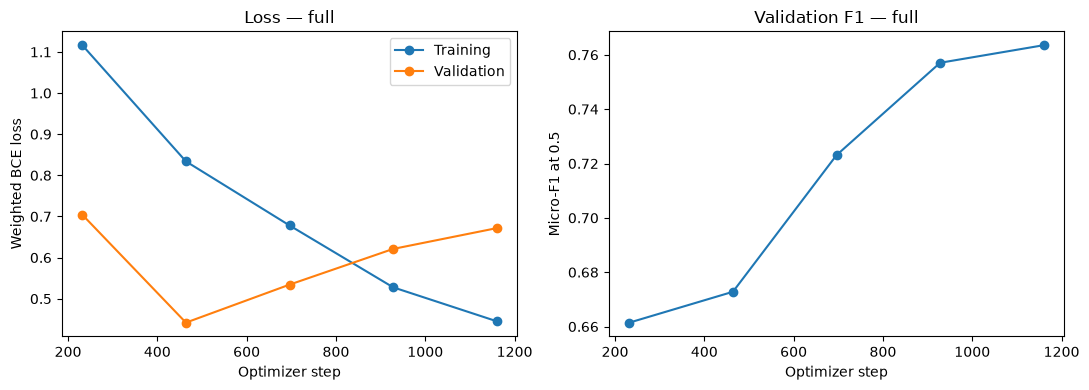

Artifacts and reports: /Users/gelo-p1/Documents/GitHub/HealthPH-Plus/artifacts/disease_xlmr/full_20261001T044257Z_9bcb95ca


In [12]:
log_history = trainer.state.log_history
write_json(REPORT_DIR / 'training_log.json', log_history)
write_json(REPORT_DIR / 'training_metrics.json', {
    'run_mode': RUN_MODE, 'smoke_only': RUN_MODE == 'smoke', **train_result.metrics,
})
logs = pd.DataFrame(log_history)
logs.to_csv(REPORT_DIR / 'training_log.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for key, label in [('loss', 'Training'), ('eval_loss', 'Validation')]:
    if key in logs:
        rows = logs.dropna(subset=[key])
        axes[0].plot(rows['step'], rows[key], marker='o', label=label)
axes[0].set(xlabel='Optimizer step', ylabel='Weighted BCE loss', title=f'Loss — {RUN_MODE}')
axes[0].legend()
if 'eval_micro_f1' in logs:
    rows = logs.dropna(subset=['eval_micro_f1'])
    axes[1].plot(rows['step'], rows['eval_micro_f1'], marker='o')
axes[1].set(xlabel='Optimizer step', ylabel='Micro-F1 at 0.5', title=f'Validation F1 — {RUN_MODE}')
fig.tight_layout()
fig.savefig(REPORT_DIR / 'training_curves.png', dpi=140)
plt.show()
print('Artifacts and reports:', RUN_DIR)


## 7. Reload the saved bundle for notebook inference

The loader reads normalization, token limit, labels, and thresholds from disk.
It needs neither the CSV nor training variables. In a fresh kernel, run only the
**imports** cell and the **loader definition** below, then pass an existing run path:

```python
predict = load_disease_predictor('/absolute/path/to/artifacts/disease_xlmr/full_<run_id>')
predict('May ubo at lagnat ako.')
```

Loading a smoke bundle requires `allow_smoke=True` explicitly. Empty label lists
are valid predictions. Blank/non-string inputs are errors. Reload verification
uses validation examples, never another test-set evaluation.


In [13]:
def load_disease_predictor(run_dir, device='auto', allow_smoke=False):
    run_dir = Path(run_dir).expanduser().resolve()
    config = json.loads((run_dir / 'run_config.json').read_text(encoding='utf-8'))
    labels = json.loads((run_dir / 'label_order.json').read_text(encoding='utf-8'))
    threshold_map = json.loads((run_dir / 'thresholds.json').read_text(encoding='utf-8'))
    expected_labels = ['AURI', 'PN', 'TB', 'COVID']
    if labels != expected_labels or config.get('label_order') != labels or set(threshold_map) != set(labels):
        raise ValueError('Saved labels/threshold keys do not match the four disease labels')
    values = [threshold_map[label] for label in labels]
    if any(type(value) not in (int, float) or not np.isfinite(value) or not 0 <= value <= 1 for value in values):
        raise ValueError('Saved thresholds must be finite numbers in [0, 1]')
    if config.get('normalization') != 'collapse whitespace and strip; preserve casing and Unicode':
        raise ValueError('Unsupported saved text normalization')
    max_length = config.get('max_length')
    if type(max_length) is not int or not 2 <= max_length <= 512:
        raise ValueError('Invalid saved token limit')
    if config.get('run_mode') not in {'full', 'smoke'} or type(config.get('smoke_only')) is not bool:
        raise ValueError('Missing or invalid run-mode metadata')
    if config['smoke_only'] != (config['run_mode'] == 'smoke'):
        raise ValueError('Inconsistent run-mode metadata')
    if config['smoke_only'] and not allow_smoke:
        raise ValueError('This is a smoke bundle, not a fully trained model; pass allow_smoke=True for diagnostics')
    target_device = select_device(str(device))
    saved_tokenizer = AutoTokenizer.from_pretrained(run_dir / 'best_model', local_files_only=True, trust_remote_code=False)
    saved_model = AutoModelForSequenceClassification.from_pretrained(
        run_dir / 'best_model', local_files_only=True, trust_remote_code=False,
    ).float().to(target_device)
    if (saved_model.config.id2label != dict(enumerate(labels))
            or saved_model.config.label2id != {label: i for i, label in enumerate(labels)}
            or saved_model.config.problem_type != 'multi_label_classification'):
        raise ValueError('Saved model configuration disagrees with bundle label mapping')
    saved_model.eval()
    threshold_array = np.array(values)

    def predict(text):
        normalized = normalize_text(text)
        inputs = saved_tokenizer(normalized, truncation=True, max_length=max_length, return_tensors='pt')
        inputs = {key: value.to(target_device) for key, value in inputs.items()}
        with torch.inference_mode():
            scores = torch.sigmoid(saved_model(**inputs).logits.float())[0].cpu().numpy()
        if scores.shape != (4,) or not np.isfinite(scores).all() or not ((scores >= 0) & (scores <= 1)).all():
            raise RuntimeError('Model returned invalid disease probabilities')
        return {
            'labels': [label for i, label in enumerate(labels) if scores[i] >= threshold_array[i]],
            'probabilities': {label: float(scores[i]) for i, label in enumerate(labels)},
            'thresholds_used': {label: float(threshold_array[i]) for i, label in enumerate(labels)},
        }

    return predict


In [14]:
# Free the training model/optimizer before loading a second copy, particularly on Mac.
validation_reference = validation_probabilities[:min(8, len(val_df))].copy()
trainer.model.to('cpu')
del trainer, model, train_ds, val_ds, test_ds, validation_output, test_output
# Adam optimizer state was owned by Trainer; release it before allocating inference weights.
gc.collect()
if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    torch.mps.empty_cache()

if RUN_MODE == 'smoke':
    expect_value_error(load_disease_predictor, RUN_DIR)
predict_disease_labels = load_disease_predictor(RUN_DIR, device=str(DEVICE), allow_smoke=(RUN_MODE == 'smoke'))
maximum_probability_difference = 0.0
for index, expected in enumerate(validation_reference):
    result = predict_disease_labels(val_df.iloc[index]['text'])
    assert set(result) == {'labels', 'probabilities', 'thresholds_used'}
    assert list(result['probabilities']) == LABELS
    assert result['thresholds_used'] == threshold_payload
    actual = np.array([result['probabilities'][label] for label in LABELS])
    np.testing.assert_allclose(actual, expected, atol=2e-5, rtol=2e-5)
    assert result['labels'] == [label for i, label in enumerate(LABELS) if expected[i] >= frozen_thresholds[i]]
    maximum_probability_difference = max(maximum_probability_difference, float(np.max(np.abs(actual - expected))))
for invalid in ['', '   ', None, 123]:
    expect_value_error(predict_disease_labels, invalid)
# Unicode, normalization, and truncation use the saved contract.
normalized_result = predict_disease_labels('May ubo at lagnat — café.')
assert predict_disease_labels('  May  ubo\n at lagnat — café.  ') == normalized_result
long_result = predict_disease_labels('ubo at lagnat ' * 300)
assert len(long_result['probabilities']) == 4

required_files = [
    'run_config.json', 'label_order.json', 'thresholds.json', 'selection.json',
    'best_model/config.json', 'best_model/model.safetensors', 'best_model/tokenizer_config.json',
    'reports/data_audit.json', 'reports/excluded_conflicting_rows.csv',
    'reports/split_manifest.csv', 'reports/active_split_manifest.csv',
    'reports/metrics.json', 'reports/per_label_metrics.csv', 'reports/test_predictions.csv',
    'reports/test_errors.csv', 'reports/confusion_matrices.csv', 'reports/training_curves.png',
]
for relative_path in required_files:
    assert (RUN_DIR / relative_path).is_file(), relative_path
write_json(REPORT_DIR / 'reload_verification.json', {
    'run_mode': RUN_MODE, 'smoke_only': RUN_MODE == 'smoke',
    'validation_examples_checked': len(validation_reference),
    'maximum_probability_difference': maximum_probability_difference,
    'probability_atol': 2e-5, 'probability_rtol': 2e-5,
    'labels_match': True, 'invalid_inputs_rejected': True,
})
print('Saved-bundle reload and inference checks passed.')
print('SMOKE RUN COMPLETE — not a trained-model benchmark.' if RUN_MODE == 'smoke' else 'Full experiment complete.')
print('Run directory:', RUN_DIR)


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 12212.17it/s]


Saved-bundle reload and inference checks passed.
Full experiment complete.
Run directory: /Users/gelo-p1/Documents/GitHub/HealthPH-Plus/artifacts/disease_xlmr/full_20261001T044257Z_9bcb95ca
